## Data Preparation

In [1]:
import torch
import numpy as np
import pandas as pd
import scanpy as sc
import squidpy as sq

import matplotlib.pyplot as plt

from pathlib import Path
from tqdm.autonotebook import tqdm

from hgctsvg.metadata import ProjectMetadata
from hgctsvg.preprocessing import common, singlecell, kidneycancer
from hgctsvg.preprocessing import visium
from hgctsvg.utils import load_ct_spatial_data, save_orig_st_data, save_decomposed_st_data

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/numcodecs/__init__.py:106: DeprecationWarning: crc32c usage is deprecated since numcodecs v0.16.4. It is recommended to install google_crc32c instead.
  from numcodecs.checksum32 import CRC32, Adler32, JenkinsLookup3
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/xarray_schema/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFou

Identify source and results directories

In [2]:
results_dir = Path("hgctsvg_project_files")
project_name = "Human Kidney Cancer Interface"

project_files_dir = results_dir / project_name
project_files_dir.mkdir(parents=True, exist_ok=True)

In [3]:
spotiphy_proj_dir = Path("spotiphy_project_files") / project_name

Load deconvolution results and spatial transcriptomics data.

Spatial transcriptomics data contains spot ids and spot locations, which are requirements for creating hyperedges.

In [4]:
adata_decomp = sc.read_h5ad(spotiphy_proj_dir / "ST_decomposition.h5ad")
adata_st = sc.read_h5ad(spotiphy_proj_dir / "Human Kidney Cancer Interface.h5ad")

The generated cell decomposition data does not yet include the cell locations generated by Spotiphy.
For visualization using Squidpy, we update adata with the generated locations.

In [5]:
adata_decomp = common.add_generated_cell_locations(spotiphy_proj_dir, adata_decomp, adata_st)

Prepared hires segmentation: (1834, 2000), 22431 cells


In [6]:
common_genes = set(adata_st.var_names).intersection(set(adata_decomp.var_names))
len(common_genes)

10849

### Make Project Metadata File

Generate a `ProjectMetadata` object. The `ProjectMetadata` file contains metadata about the project, which is used in several parts of the pipeline:
- `project_folder` - directory of the project.
- `ct_key` - cell type key used by adata objects to indicate the cell type of each cell.
- `ct_list` - list of cell types sorted in lexicographical order.
- `ct_mapping` - mapping of cell type names (`str`) to their positions in the `ct_list` (`int`). `ct_mapping` is important when preparing and accessing data in the pipeline.
- `n_cell_types` - number of cell types in the data.
- `dir_map` - mapping of directories to project subfolders

Creating `ProjectMetadata` requires `ct_key` as an argument, but once created, `ct_key` can also be accessed from the `ProjectMetadata`.

In [7]:
project_metadata = ProjectMetadata.create(project_files_dir, 
                             adata_decomp,
                             'cell_type')
# ct_metadata.ct_key, ct_metadata.ct_list, ct_metadata.ct_mapping, ct_metadata.n_cell_types

In [8]:
project_metadata.dir_map

{'attr_dir': 'attribution',
 'classifier_dir': 'classifiers',
 'clustering_dir': 'clustering',
 'ct_data_dir': 'ct_spatial_data',
 'plot_dir': 'plots',
 'eval_dir': 'evaluation'}

## Preprocessing

Preprocess original and decomposed ST data.

### General Preprocessing
Preprocess original ST data using standard preprocessing steps. Also perform HVG selection.

In [9]:
# Preprocessing and HVG detection
n_top_genes = 3000

# filter first before preprocess
print(adata_decomp.shape)
print(adata_st.shape)
adata_decomp = common.filter(adata_decomp, min_genes=20, min_locs=20)
adata_st = common.filter(adata_st, min_genes=20, min_locs=20)
print(adata_decomp.shape)
print(adata_st.shape)

# Preprocess ST data.
# Store unprocessed data to raw.
# Raw data is needed for visualization.
adata_st.raw = adata_st.copy()
sc.pp.highly_variable_genes(adata_st, flavor='seurat_v3', n_top_genes=n_top_genes)
sc.pp.normalize_total(adata_st, target_sum=1e6)
sc.pp.log1p(adata_st)

(22431, 10849)
(2048, 15222)
(22431, 10810)
(2048, 13213)


Save the preprocessed ```adata_decomp``` and ```adata_st``` in the project folder 

In [10]:
# save adata_st
save_orig_st_data(adata_st)

# save adata_decomp
save_decomposed_st_data(adata_decomp)
# adata_decomp.write_h5ad(project_files_dir / "ST_decomposition.h5ad")

### Create separate anndata objects for each cell type.

For the decomposed data, we first separate them into different anndata objects per cell type using `preprocessing.singlecell.make_ct_spatial_data`, which also performs preprocessing on each anndata object separately. 

Then, get the top genes per cell type using `preprocessing.singlecell.perform_ct_feature_selection`.

In [11]:
n_features=3000
# singlecell.make_ct_spatial_adata(adata_decomp)
# singlecell.perform_ct_feature_selection(n_features=n_features)

Visualize the resulting anndata objects.

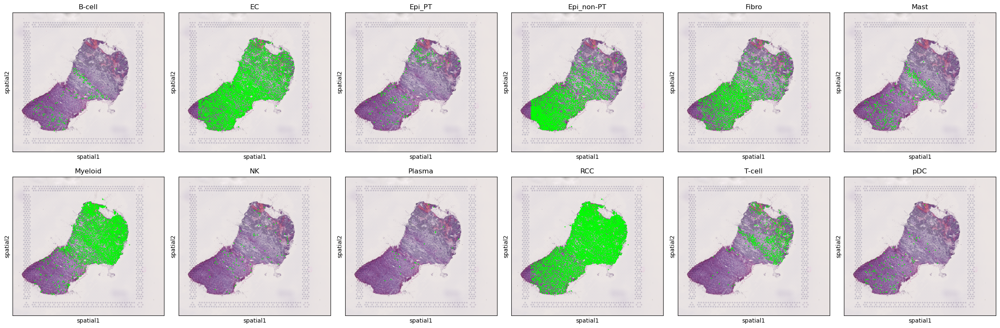

In [12]:
from hgctsvg.visualization import plot_all_ct_decomposition, plot_ct_decomposition
plot_all_ct_decomposition(n_cols=6)

# use this to plot each cell type separately
# plot_ct_decomposition(display=False, show_title=False)

Also visualize the distribution of genes on the original ST anndata object.

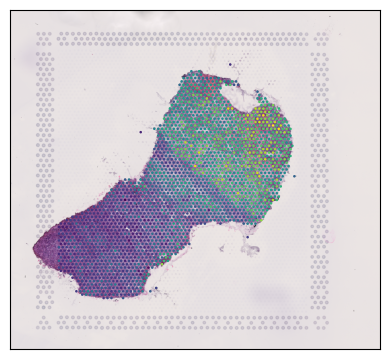

In [13]:
from hgctsvg.visualization import plot_st_gene_counts

plot_st_gene_counts(show_title=False, display=True)

## ML Dataset Creation

Create the Hypergraph Data for the ML pipeline.

In [14]:
# hgdata = visium.create_hypergraph_data(adata_st, n_features=n_features, num_neighbor_spots=7)
# hgdata.save()

# HGCTSVG Pipeline

For each step of the pipeline, run the following commands:

## I. Embedding Learning

```bash
# Using CUDA
CUDA_VISIBLE_DEVICES=1 hgctsvg train-embedder --project "Human Kidney Cancer Interface" \
--model.model-name HyFiEmbedder --model.input-dim 3000 --model.embedding-dim 50 --model.dropout 0.2 \
--trainer.num_epochs 1000 --trainer.batch_size 22431 --trainer.accelerator cuda
```

```bash
# Using CPU
hgctsvg train-embedder --project "Human Kidney Cancer Interface" \
--model.model-name HyFiEmbedder --model.input-dim 3000 --model.embedding-dim 50 --model.dropout 0.2 \
--trainer.num_epochs 1000 --trainer.batch_size 22431 --trainer.accelerator cpu
```

## II. Embedding Generation

```bash
# Using CUDA
CUDA_VISIBLE_DEVICES=1 hgctsvg make-embedding --project "Human Kidney Cancer Interface" \
--model.model-name HyFiEmbedder --model.input-dim 3000 --model.embedding-dim 50 --model.dropout 0.2 \
--trainer.num_epochs 100 --trainer.batch_size 22431 --trainer.accelerator cuda
```

```bash
# Using CPU
hgctsvg make-embedding --project "Human Kidney Cancer Interface" \
--model.model-name HyFiEmbedder --model.input-dim 3000 --model.embedding-dim 50 --model.dropout 0.2 \
--trainer.num_epochs 100 --trainer.batch_size 22431 --trainer.accelerator cpu
```

## III. Spatial Domain Identification

```bash
hgctsvg compute-spatial-domains --project "Human Kidney Cancer Interface" 
```

## IV. Cell-type Specific Domain Identification

```bash
hgctsvg compute-celltype-spatial-domains --project "Human Kidney Cancer Interface" \
--data.cell-type-key "cell_type"
```

## V. Classifier Training

```bash
# Using CUDA
CUDA_VISIBLE_DEVICES=1 hgctsvg train-celltype-domain-classifiers --project "Human Kidney Cancer Interface" \
--classifier.embedding-dim 50 --classifier.num_layers 3 \
--trainer.num_epochs 1000 --trainer.batch_size 4096 --trainer.accelerator cuda
```

```bash
# Using CPU
hgctsvg train-classifier --project "Human Kidney Cancer Interface" \
--classifier.embedding-dim 50 --classifier.num_layers 3 \
--trainer.num_epochs 1000 --trainer.batch_size 4096 --trainer.accelerator cpu
```

## VI. Spatial Metagene Computation

### A. Compute Metagene Attribution to a Cell Type Spatial Domain
```bash
# Using CUDA
CUDA_VISIBLE_DEVICES=1 hgctsvg compute-cell-embedding-attributions --project "Human Kidney Cancer Interface" \
--cell_type EC \
--classifier.embedding-dim 50 --classifier.num_layers 3 \
--attribution.n_steps 1000 --attribution.accelerator cuda
```

```bash
# Using CPU
hgctsvg compute-cell-embedding-attributions --project "Human Kidney Cancer Interface" \
--cell_type EC \
--classifier.embedding-dim 50 --classifier.num_layers 3 \
--attribution.n_steps 1000 --attribution.accelerator cpu
```

### B. Compute Gene Attribution to Metagene

```bash
# Train Embedder
CUDA_VISIBLE_DEVICES=0 hgctsvg train-embedder --project "Human Kidney Cancer Interface" --model.model-name CTHGCAEEmbedder --model.input-dim 3000 --model.embedding-dim 200 --model.latent-dim 500 --model.dropout 0.2 --trainer.num_epochs 1000 --trainer.batch_size 22431 --trainer.accelerator cuda
# Make Embedding
CUDA_VISIBLE_DEVICES=0 hgctsvg make-embedding --project "Human Kidney Cancer Interface" --model.model-name CTHGCAEEmbedder --model.input-dim 3000 --model.embedding-dim 200 --model.latent-dim 500 --model.dropout 0.2 --trainer.num_epochs 1000 --trainer.batch_size 22431 --trainer.accelerator cuda
# Compute Tissue-Wide Spatial Domains
hgctsvg compute-spatial-domains --project "Human Kidney Cancer Interface" --clustering.min_cluster_pct 0.05 --clustering.algorithm leiden
# Compute Cell-Type-Specific Spatial Domains
hgctsvg compute-celltype-spatial-domains --project "Human Kidney Cancer Interface" --clustering.min_cluster_pct 0.05 --clustering.algorithm leiden

# CUDA_VISIBLE_DEVICES=0 hgctsvg train-celltype-domain-classifiers --project "Human Kidney Cancer Interface" --classifier.embedding-dim 200 --classifier.num_layers 3 --trainer.num_epochs 1000 --trainer.batch_size 4096 --trainer.accelerator cuda
# CUDA_VISIBLE_DEVICES=0 hgctsvg compute-gene-to-celltype-domain-attribution --project "Human Kidney Cancer Interface" --cell-type RCC --model.model-name CTHGCAEEmbedder --model.input-dim 3000 --model.embedding-dim 200 --model.latent-dim 500 --classifier.embedding-dim 200 --classifier.num_layers 3 --explainer.n_steps 100 --explainer.batch-size 8192 --explainer.accelerator cuda

# Perform Model Evaluation
CUDA_VISIBLE_DEVICES=0 hgctsvg perform-model-evaluation --project "Human Kidney Cancer Interface" --model.model-name CTHGCAEv2Embedder --model.input-dim 3000 --model.embedding-dim 200 --model.latent-dim 500 --model.dropout 0.2 --trainer.num_epochs 1000 --trainer.batch_size 22431 --trainer.accelerator cuda --clustering.min_cluster_pct -1 --clustering.algorithm leiden --num_runs 10

# CUDA_VISIBLE_DEVICES=0 hgctsvg compute-cell-embedding-attributions --project "Human Kidney Cancer Interface" --classifier.embedding-dim 200 --classifier.num_layers 3 --explainer.n_steps 1000 --explainer.accelerator cuda
# CUDA_VISIBLE_DEVICES=0 hgctsvg compute-metagene-to-region-attribution --project "Human Kidney Cancer Interface" --cell-type EC --region 0 --classifier.embedding-dim 200 --classifier.num_layers 3 --explainer.n_steps 1000 --explainer.accelerator cuda
# CUDA_VISIBLE_DEVICES=0 hgctsvg compute-gene-to-cell-metagene-attribution --project "Human Kidney Cancer Interface" --model.model-name SpatialFusionEmbedder --model.input-dim 3000 --model.embedding-dim 200 --model.latent-dim 500 --explainer.n_steps 100 --explainer.batch-size 8192 --explainer.accelerator cuda

```

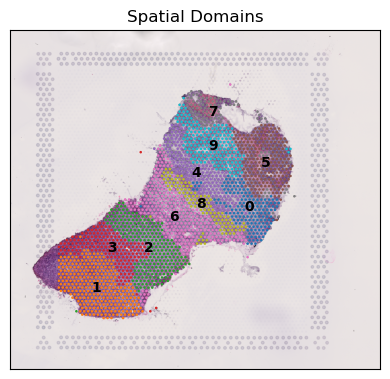

In [15]:
from hgctsvg.visualization import plot_aggr_st_domains

plot_aggr_st_domains(show_title=False)
plot_aggr_st_domains(show_title=True, display=True, save=False)

In [16]:
adata_decomp.obs_names

Index(['0', '1', '2', '3', '4', '5', '6', '7', '8', '9',
       ...
       '22421', '22422', '22423', '22424', '22425', '22426', '22427', '22428',
       '22429', '22430'],
      dtype='object', length=22431)

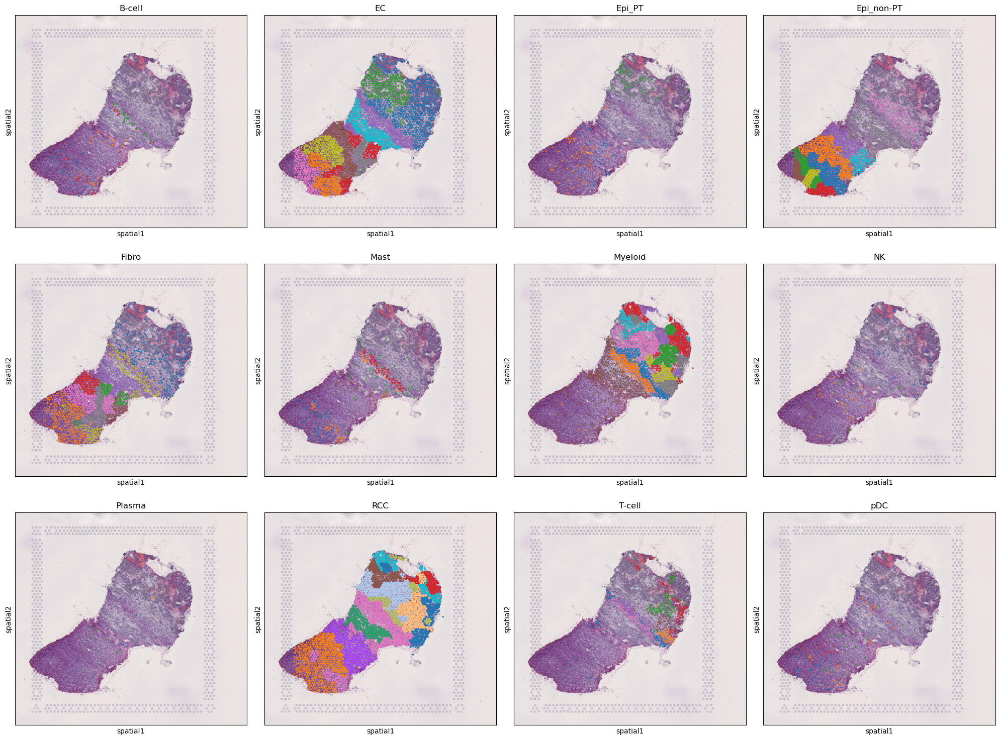

In [17]:
from hgctsvg.visualization import plot_all_ct_domains

plot_all_ct_domains()

In [18]:
from hgctsvg.visualization import plot_ct_domains
plot_ct_domains(show_title=True)

/workspace/HGCTSVG/hgctsvg/src/hgctsvg/visualization/ct.py:150: UserWarning: The figure layout has changed to tight
  plt.tight_layout()
/workspace/HGCTSVG/hgctsvg/src/hgctsvg/visualization/ct.py:150: UserWarning: The figure layout has changed to tight
  plt.tight_layout()
/workspace/HGCTSVG/hgctsvg/src/hgctsvg/visualization/ct.py:150: UserWarning: The figure layout has changed to tight
  plt.tight_layout()
/workspace/HGCTSVG/hgctsvg/src/hgctsvg/visualization/ct.py:150: UserWarning: The figure layout has changed to tight
  plt.tight_layout()
/workspace/HGCTSVG/hgctsvg/src/hgctsvg/visualization/ct.py:150: UserWarning: The figure layout has changed to tight
  plt.tight_layout()
/workspace/HGCTSVG/hgctsvg/src/hgctsvg/visualization/ct.py:150: UserWarning: The figure layout has changed to tight
  plt.tight_layout()
/workspace/HGCTSVG/hgctsvg/src/hgctsvg/visualization/ct.py:150: UserWarning: The figure layout has changed to tight
  plt.tight_layout()
/workspace/HGCTSVG/hgctsvg/src/hgctsvg/vi

In [19]:
from hgctsvg.utils import load_aggr_st_data

adata_aggr = load_aggr_st_data()
adata_aggr.obs['domain'].value_counts()

domain
1    302
6    296
2    257
5    233
9    201
3    186
0    166
4    164
8    119
7    111
Name: count, dtype: int64

In [20]:
adata_aggr.obs['domain'].astype(int).tolist()

[0,
 1,
 1,
 2,
 3,
 1,
 4,
 5,
 6,
 1,
 1,
 1,
 2,
 2,
 4,
 3,
 0,
 4,
 5,
 6,
 7,
 1,
 6,
 5,
 7,
 3,
 6,
 8,
 9,
 5,
 3,
 2,
 3,
 7,
 3,
 3,
 9,
 5,
 5,
 1,
 1,
 1,
 6,
 0,
 9,
 8,
 9,
 1,
 9,
 5,
 9,
 6,
 2,
 2,
 7,
 4,
 2,
 6,
 0,
 3,
 9,
 9,
 1,
 2,
 8,
 4,
 4,
 2,
 9,
 1,
 3,
 6,
 4,
 0,
 9,
 1,
 9,
 1,
 1,
 9,
 0,
 0,
 2,
 0,
 3,
 1,
 5,
 2,
 3,
 1,
 2,
 8,
 5,
 2,
 5,
 1,
 4,
 3,
 5,
 0,
 3,
 3,
 6,
 5,
 5,
 4,
 5,
 1,
 3,
 1,
 6,
 1,
 6,
 9,
 1,
 6,
 8,
 1,
 7,
 1,
 6,
 8,
 4,
 6,
 6,
 3,
 0,
 9,
 4,
 0,
 9,
 1,
 5,
 1,
 0,
 4,
 7,
 9,
 2,
 3,
 7,
 3,
 1,
 4,
 2,
 0,
 6,
 6,
 8,
 7,
 0,
 6,
 1,
 5,
 2,
 8,
 0,
 6,
 6,
 6,
 6,
 4,
 1,
 1,
 2,
 0,
 6,
 2,
 3,
 8,
 5,
 9,
 1,
 4,
 0,
 0,
 0,
 1,
 1,
 2,
 3,
 5,
 1,
 3,
 1,
 7,
 3,
 1,
 5,
 9,
 4,
 5,
 7,
 2,
 5,
 8,
 9,
 6,
 6,
 2,
 8,
 5,
 5,
 2,
 2,
 6,
 1,
 3,
 9,
 1,
 7,
 1,
 8,
 4,
 3,
 4,
 6,
 6,
 5,
 2,
 9,
 1,
 2,
 0,
 0,
 1,
 7,
 2,
 9,
 1,
 1,
 3,
 5,
 6,
 3,
 4,
 8,
 8,
 8,
 1,
 9,
 3,
 4,
 8,
 4,
 0,
 6,
 8,
 1,
 9,


In [21]:
adata_st2 = adata_st[adata_aggr.obs_names]
adata_st2

View of AnnData object with n_obs × n_vars = 2035 × 13213
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'mt_frac', 'donor_id', 'region', 'n_genes'
    var: 'feature_types', 'genome', 'SYMBOL', 'mt', 'n_cells_by_counts-6800STDY12499411', 'mean_counts-6800STDY12499411', 'log1p_mean_counts-6800STDY12499411', 'pct_dropout_by_counts-6800STDY12499411', 'total_counts-6800STDY12499411', 'log1p_total_counts-6800STDY12499411', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'sample_colors', 'spatial', 'hvg', 'log1p'
    obsm: 'spatial'

In [22]:
import torch
embedding = torch.load(project_metadata.project_folder / "hyperedge_embeddings.pth")

nan_mask = torch.isnan(embedding)
nan_rows = torch.any(nan_mask, dim=1)
embedding = embedding[~nan_rows]
embedding = embedding.numpy()
adata_st2.obsm['embedding'] = embedding
adata_st2.obs['domain_embedding'] = adata_aggr.obs['domain']

/tmp/ipykernel_411691/1069502697.py:8: ImplicitModificationWarning: Setting element `.obsm['embedding']` of view, initializing view as actual.
  adata_st2.obsm['embedding'] = embedding


In [23]:
adata_st2

AnnData object with n_obs × n_vars = 2035 × 13213
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'mt_frac', 'donor_id', 'region', 'n_genes', 'domain_embedding'
    var: 'feature_types', 'genome', 'SYMBOL', 'mt', 'n_cells_by_counts-6800STDY12499411', 'mean_counts-6800STDY12499411', 'log1p_mean_counts-6800STDY12499411', 'pct_dropout_by_counts-6800STDY12499411', 'total_counts-6800STDY12499411', 'log1p_total_counts-6800STDY12499411', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'sample_colors', 'spatial', 'hvg', 'log1p'
    obsm: 'spatial', 'embedding'

In [24]:
adata_st2.uns.keys()

dict_keys(['sample_colors', 'spatial', 'hvg', 'log1p'])

In [25]:
sc.pp.neighbors(adata_st2)
sc.tl.leiden(adata_st2)

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/scanpy/neighbors/__init__.py:577: UserWarning: You’re trying to run this on 13213 dimensions of `.X`, if you really want this, set `use_rep='X'`.
         Falling back to preprocessing with `sc.pp.pca` and default params.
  x = _choose_representation(self._adata, use_rep=use_rep, n_pcs=n_pcs)
/tmp/ipykernel_411691/3072798649.py:2: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(adata_st2)


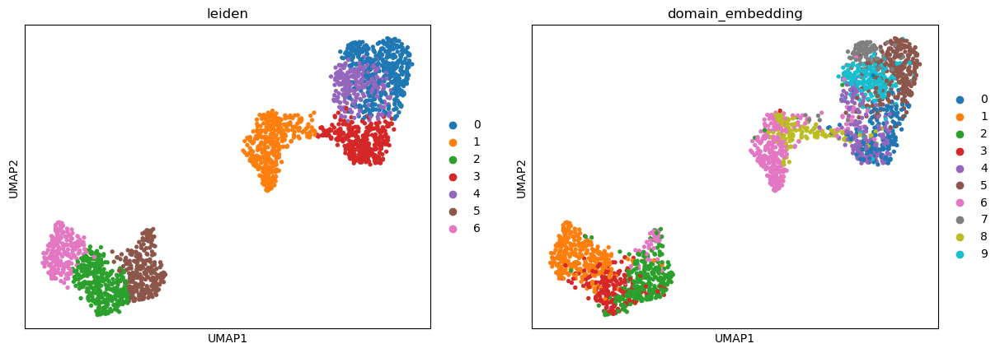

In [26]:
sc.tl.umap(adata_st2)
sc.pl.umap(adata_st2, color=['leiden', 'domain_embedding'])

In [27]:
sc.tl.rank_genes_groups(adata_aggr, 
                        groupby='domain',
                        method="wilcoxon",
                        pts=True,
                        use_raw=False)

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/scanpy/tools/_dendrogram.py:138: UserWarning: You’re trying to run this on 10810 dimensions of `.X`, if you really want this, set `use_rep='X'`.
         Falling back to preprocessing with `sc.pp.pca` and default params.
  _choose_representation(adata, use_rep=use_rep, n_pcs=n_pcs)


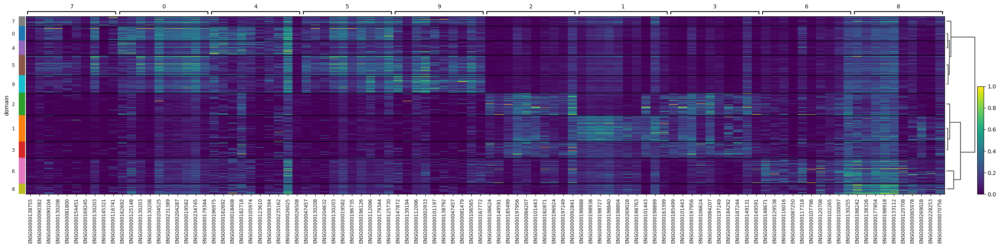

In [28]:
sc.tl.dendrogram(adata_aggr, groupby='domain')
sc.pl.rank_genes_groups_heatmap(
    adata_aggr,
    n_genes=10,
    standard_scale="var",
    show_gene_labels=True,
)

In [29]:
adata_RCC = load_ct_spatial_data("RCC")
adata_RCC

AnnData object with n_obs × n_vars = 7951 × 10693
    obs: 'cell_type', 'spot_name', 'n_cell', 'location_x', 'location_y', 'library_id', 'segmentation', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'n_genes', 'cell_idx', 'domain'
    var: 'SYMBOL', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'feature_gene'
    uns: 'cell_count', 'domain', 'hvg', 'log1p', 'neighbors', 'sample_colors', 'spatial'
    obsm: 'cell_nucleus', 'embedding', 'spatial'
    obsp: 'connectivities', 'distances'

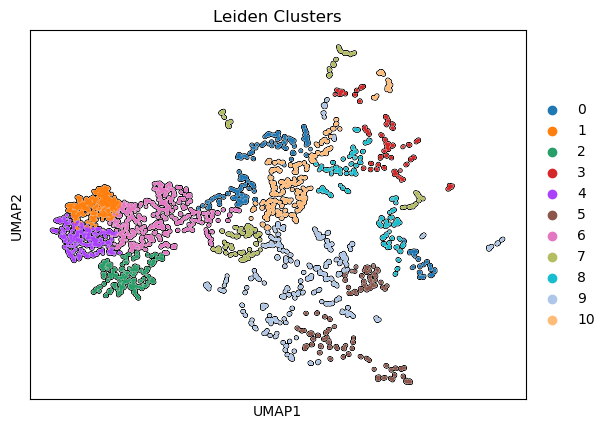

In [30]:
from scipy import sparse

sc.pp.neighbors(adata_RCC, use_rep='embedding', knn=False, method='gauss', key_added='umap')
adata_RCC.obsp['connectivities'] = sparse.csr_matrix(adata_RCC.obsp['connectivities'])
sc.tl.umap(adata_RCC)
sc.pl.umap(adata_RCC, color='domain', title='Leiden Clusters', add_outline=True)

In [31]:
adata_decomp

AnnData object with n_obs × n_vars = 22431 × 10810
    obs: 'cell_type', 'spot_name', 'n_cell', 'location_x', 'location_y', 'library_id', 'segmentation', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'n_genes'
    var: 'SYMBOL', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    uns: 'cell_count', 'sample_colors', 'spatial'
    obsm: 'cell_nucleus', 'spatial'

In [32]:
adata_RCC

AnnData object with n_obs × n_vars = 7951 × 10693
    obs: 'cell_type', 'spot_name', 'n_cell', 'location_x', 'location_y', 'library_id', 'segmentation', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'n_genes', 'cell_idx', 'domain'
    var: 'SYMBOL', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'feature_gene'
    uns: 'cell_count', 'domain', 'hvg', 'log1p', 'neighbors', 'sample_colors', 'spatial', 'umap', 'domain_colors'
    obsm: 'cell_nucleus', 'embedding', 'spatial', 'X_umap'
    obsp: 'connectivities', 'distances', 'umap_distances', 'umap_connectivities'

In [33]:
adata_RCC.obs['domain'].value_counts()

domain
6     1263
9     1145
10     931
1      779
0      659
4      624
2      618
5      557
8      504
7      468
3      403
Name: count, dtype: int64

In [34]:
sc.tl.rank_genes_groups(adata_RCC, 
                        groupby='domain',
                        method="wilcoxon",
                        pts=True,
                        use_raw=False)

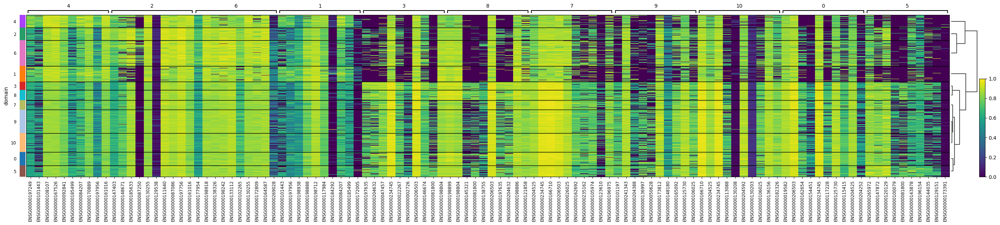

In [35]:
# sc.tl.dendrogram(adata_RCC, groupby='leiden')
sc.tl.dendrogram(adata_RCC, var_names=adata_RCC.var_names[adata_RCC.var['feature_gene']], groupby='domain')
sc.pl.rank_genes_groups_heatmap(
    adata_RCC,
    n_genes=10,
    standard_scale="var",
    # standard_scale="obs",
    # vmin=adata_RCC.X[adata_RCC.X > 0].min(),
    log=True,
    show_gene_labels=True,
)

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/scanpy/tools/_dendrogram.py:138: UserWarning: You’re trying to run this on 10693 dimensions of `.X`, if you really want this, set `use_rep='X'`.
         Falling back to preprocessing with `sc.pp.pca` and default params.
  _choose_representation(adata, use_rep=use_rep, n_pcs=n_pcs)


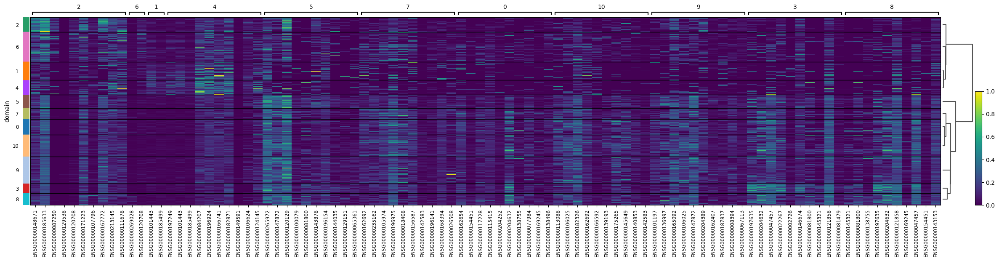

In [36]:
from hgctsvg.pipeline import compute_domain_ct_svgs, create_svg_list
from hgctsvg.visualization import plot_ct_marker_groups_heatmap

top_genes_RCC = compute_domain_ct_svgs("RCC", rank_by='scores')
plot_ct_marker_groups_heatmap(adata_RCC, top_genes_RCC)

In [37]:
top_genes_RCC

{'0':                 names     scores  logfoldchanges          pvals  \
 2     ENSG00000162654  22.083622        3.035463  4.541840e-108   
 3     ENSG00000154451  21.679983        3.626110  3.169894e-104   
 5     ENSG00000117228  20.614035        3.321684   2.053770e-94   
 7     ENSG00000115415  19.559578        2.464335   3.418960e-85   
 9     ENSG00000204252  18.829317        2.741519   4.343324e-79   
 ...               ...        ...             ...            ...   
 1692  ENSG00000086300   5.242754        1.531370   1.581978e-07   
 1986  ENSG00000025708   4.862215        1.570978   1.160798e-06   
 1999  ENSG00000167772   4.855091        1.612131   1.203317e-06   
 3193  ENSG00000148926   3.699491        1.527944   2.160321e-04   
 5146  ENSG00000110092   2.354650        1.529319   1.854015e-02   
 
           pvals_adj  pct_nz_group  pct_nz_reference       pts  pts_rest  
 2     1.618863e-104      0.963581          0.615606  0.963581  0.615606  
 3     8.473919e-101      0

In [38]:
for group in top_genes_RCC:
    print(len(top_genes_RCC[group]))

165
2
20
601
10
174
2
251
150
184
398


In [39]:
top_genes_RCC['0']

,names,scores,logfoldchanges,pvals,pvals_adj,pct_nz_group,pct_nz_reference,pts,pts_rest
2,ENSG00000162654,22.083622,3.035463,4.541840e-108,1.618863e-104,0.963581,0.615606,0.963581,0.615606
3,ENSG00000154451,21.679983,3.626110,3.169894e-104,8.473919e-101,0.886191,0.426906,0.886191,0.426906
5,ENSG00000117228,20.614035,3.321684,2.053770e-94,3.660161e-91,0.962064,0.575014,0.962064,0.575014
7,ENSG00000115415,19.559578,2.464335,3.418960e-85,4.569868e-82,1.000000,0.767553,1.000000,0.767553
9,ENSG00000204252,18.829317,2.741519,4.343324e-79,3.870264e-76,0.919575,0.518376,0.919575,0.518376
...,...,...,...,...,...,...,...,...,...
1692,ENSG00000086300,5.242754,1.531370,1.581978e-07,9.371795e-07,0.831563,0.622052,0.831563,0.622052
1986,ENSG00000025708,4.862215,1.570978,1.160798e-06,5.885450e-06,0.977238,0.723533,0.977238,0.723533
1999,ENSG00000167772,4.855091,1.612131,1.203317e-06,6.060797e-06,0.962064,0.786341,0.962064,0.786341
3193,ENSG00000148926,3.699491,1.527944,2.160321e-04,6.844535e-04,0.869499,0.672518,0.869499,0.672518


In [40]:
top_genes_RCC_merged = create_svg_list(top_genes_RCC)
len(top_genes_RCC_merged)

840

In [41]:
top_genes_RCC_merged

,scores,adjusted p-vals,region
ENSG00000162654,22.083622,1.618863e-104,0
ENSG00000154451,21.679983,8.473919e-101,0
ENSG00000117228,20.614035,3.660161e-91,0
ENSG00000115415,19.559578,4.569868e-82,0
ENSG00000204252,18.829317,3.870264e-76,0
...,...,...,...
ENSG00000266472,8.421422,4.971479e-16,9
ENSG00000087266,8.286197,1.486692e-15,9
ENSG00000010404,7.756720,9.030445e-14,9
ENSG00000198561,7.616707,2.598158e-13,9


In [42]:
from hgctsvg.pipeline import compute_domain_svgs

top_genes = compute_domain_svgs(rank_by='scores')
top_gene_list = create_svg_list(top_genes)
len(top_gene_list)

1002

In [43]:
top_gene_list

,scores,adjusted p-vals,region
ENSG00000162692,15.899353,6.920783e-53,0
ENSG00000125148,15.567183,6.574994e-51,0
ENSG00000105974,14.086478,4.143214e-42,0
ENSG00000196975,13.780497,2.005663e-40,0
ENSG00000182718,13.668165,8.502717e-40,0
...,...,...,...
ENSG00000188290,4.573920,5.768738e-05,9
ENSG00000099977,4.511709,7.458835e-05,9
ENSG00000167397,4.188514,2.727145e-04,9
ENSG00000137312,3.093241,9.537430e-03,9


In [44]:
for g in sorted(top_genes_RCC_merged['region'].unique()):
    print(g, len(top_genes_RCC_merged[top_genes_RCC_merged['region'] == g]))

0 28
1 1
10 255
2 16
3 297
4 9
5 64
6 1
7 62
8 22
9 85


In [45]:
top_genes_RCC_merged[top_genes_RCC_merged['region'] == '0']

,scores,adjusted p-vals,region
ENSG00000162654,22.083622,1.618863e-104,0
ENSG00000154451,21.679983,8.473919e-101,0
ENSG00000117228,20.614035,3.660161e-91,0
ENSG00000115415,19.559578,4.569868e-82,0
ENSG00000204252,18.829317,3.870264e-76,0
ENSG00000138496,16.929651,1.321991e-61,0
ENSG00000125347,15.612277,1.528964e-52,0
ENSG00000115310,14.343778,2.225196e-44,0
ENSG00000162512,14.276757,5.444320e-44,0
ENSG00000196954,13.836924,2.435422e-41,0


In [46]:
adata_decomp.var

,SYMBOL,n_cells_by_counts,mean_counts,log1p_mean_counts,pct_dropout_by_counts,total_counts,log1p_total_counts,n_cells
ENSEMBL,,,,,,,,
ENSG00000174080,CTSF,10146,114.789702,4.751776,54.767955,2.574848e+06,14.761301,10146
ENSG00000177646,ACAD9,4232,28.092147,3.370468,81.133253,6.301350e+05,13.353691,4232
ENSG00000176273,SLC35G1,642,3.398424,1.481246,97.137890,7.623004e+04,11.241524,642
ENSG00000197756,RPL37A,22396,3529.999097,8.169336,0.156034,7.918141e+07,18.187252,22396
ENSG00000109971,HSPA8,17816,362.393104,5.895485,20.574205,8.128840e+06,15.910929,17816
...,...,...,...,...,...,...,...,...
ENSG00000175449,RFESD,352,2.064262,1.119807,98.430743,4.630345e+04,10.742993,352
ENSG00000061936,SFSWAP,5339,34.059508,3.557047,76.198119,7.639888e+05,13.546310,5339
ENSG00000126106,TMEM53,1387,10.886287,2.475385,93.816593,2.441903e+05,12.405707,1387


In [48]:
adata_aggr.var["SYMBOL"] = adata_decomp.var["SYMBOL"]

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/

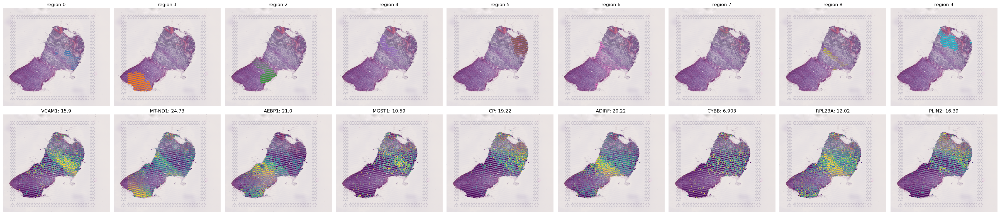

In [49]:
from hgctsvg.visualization import plot_domain_svgs

# groups = adata_RCC.obs['leiden'].unique()
groups = sorted(top_gene_list['region'].unique(), key=lambda r: int(r))
plot_domain_svgs(adata_aggr, top_gene_list, groups, n_cols=len(groups), save=True)

In [50]:
groups

['0', '1', '2', '4', '5', '6', '7', '8', '9']

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/

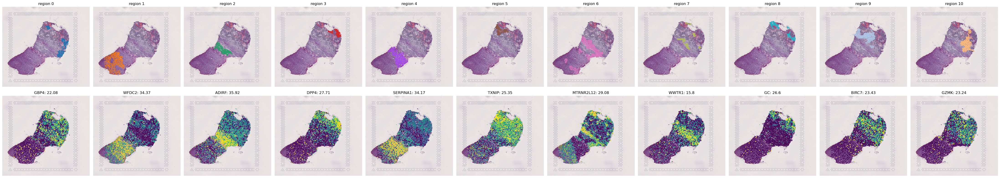

In [51]:
# groups = adata_RCC.obs['leiden'].unique()
groups = sorted(top_genes_RCC_merged['region'].unique(), key=lambda r: int(r))
plot_domain_svgs(adata_RCC, top_genes_RCC_merged, groups, n_cols=12, save=True)

In [52]:
# groups = adata_RCC.obs['leiden'].unique()
# groups = ['2','5','8','11','16','18','20','22']
# plot_domain_svgs(adata_RCC, top_genes_RCC_merged, groups, n_cols=8, save=True)

In [53]:
rcc_svgs = top_genes_RCC_merged.index
tissue_svgs = top_gene_list.index
union = rcc_svgs.union(tissue_svgs)
intersection = rcc_svgs.intersection(tissue_svgs)
len(rcc_svgs), len(tissue_svgs), len(union), len(intersection), len(intersection)/len(union)

(840, 1002, 1227, 615, 0.5012224938875306)

In [54]:
top_genes_RCC_merged.loc[rcc_svgs.difference(tissue_svgs)].sort_values("scores",ascending=False)

,scores,adjusted p-vals,region
ENSG00000087250,32.230923,1.740666e-224,2
ENSG00000145321,26.604328,2.156049e-152,8
ENSG00000002726,24.133900,1.683510e-125,3
ENSG00000100079,21.519403,2.739298e-99,5
ENSG00000144035,21.149851,3.700005e-96,5
...,...,...,...
ENSG00000168090,4.125366,9.623073e-05,3
ENSG00000243056,4.008543,1.537141e-04,3
ENSG00000141002,3.715204,4.694288e-04,3
ENSG00000125520,3.664989,5.643077e-04,3


In [55]:
top_gene_list.loc[tissue_svgs.difference(rcc_svgs)].sort_values("scores",ascending=False)

,scores,adjusted p-vals,region
ENSG00000198888,24.734760,4.889270e-131,1
ENSG00000198727,23.094139,1.432989e-114,1
ENSG00000198840,22.173651,1.111588e-105,1
ENSG00000198804,21.687088,4.194956e-101,1
ENSG00000198763,20.885454,8.721271e-94,1
...,...,...,...
ENSG00000241553,2.282461,4.837929e-02,0
ENSG00000185825,2.276259,4.907497e-02,0
ENSG00000170906,2.256399,3.555859e-02,5
ENSG00000145494,2.218426,3.885942e-02,5


/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]


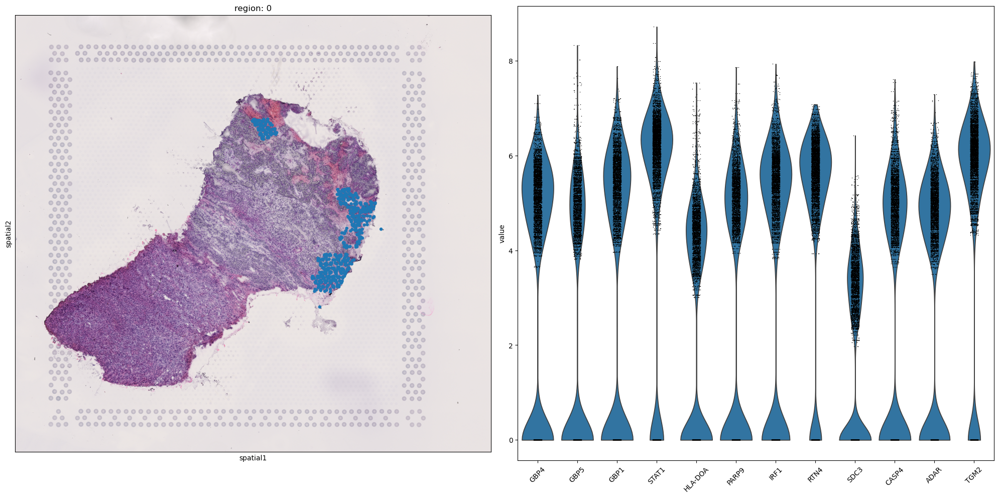

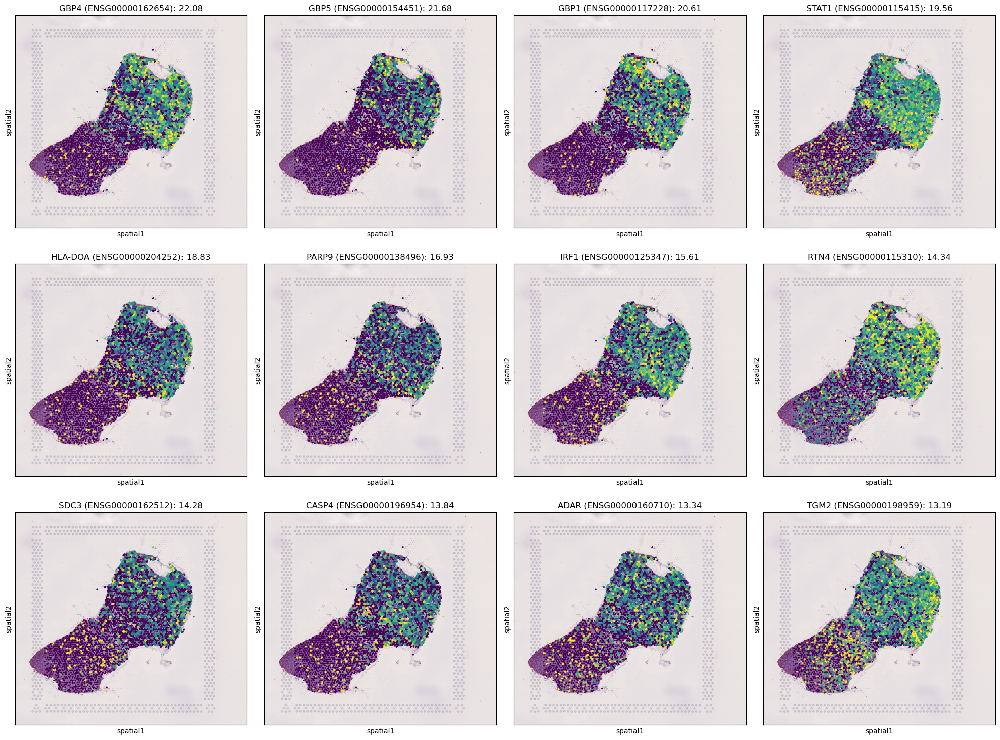

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]


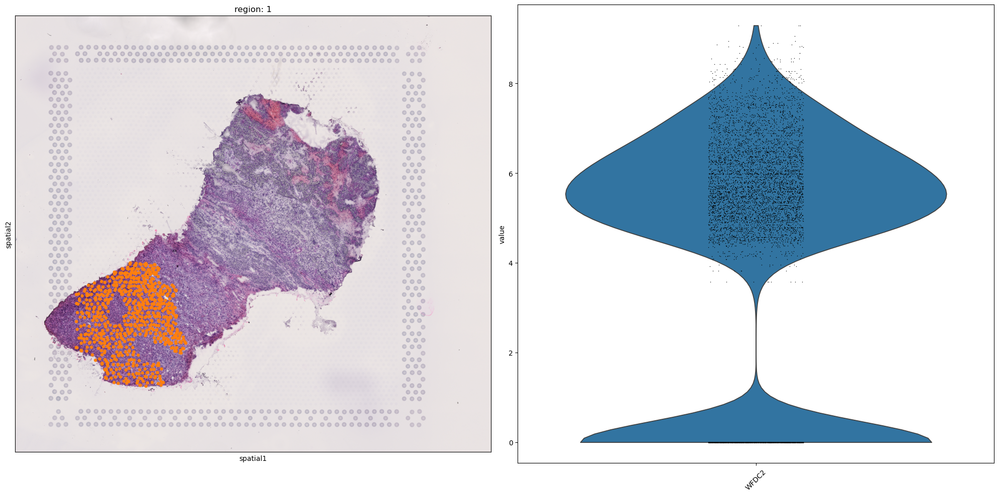

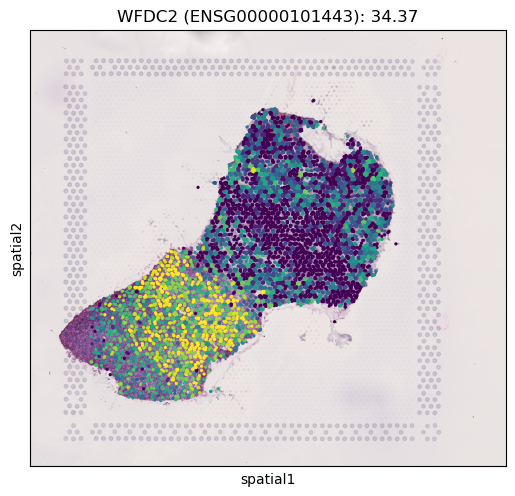

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]


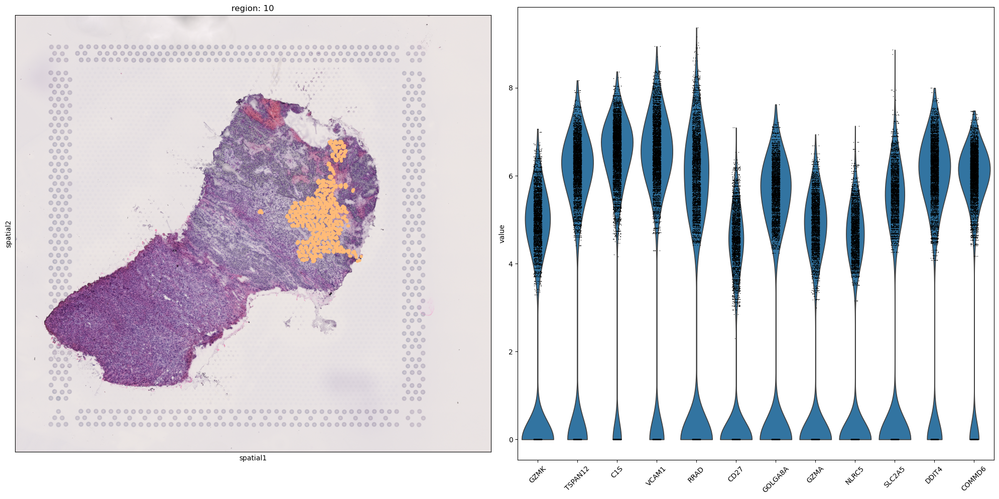

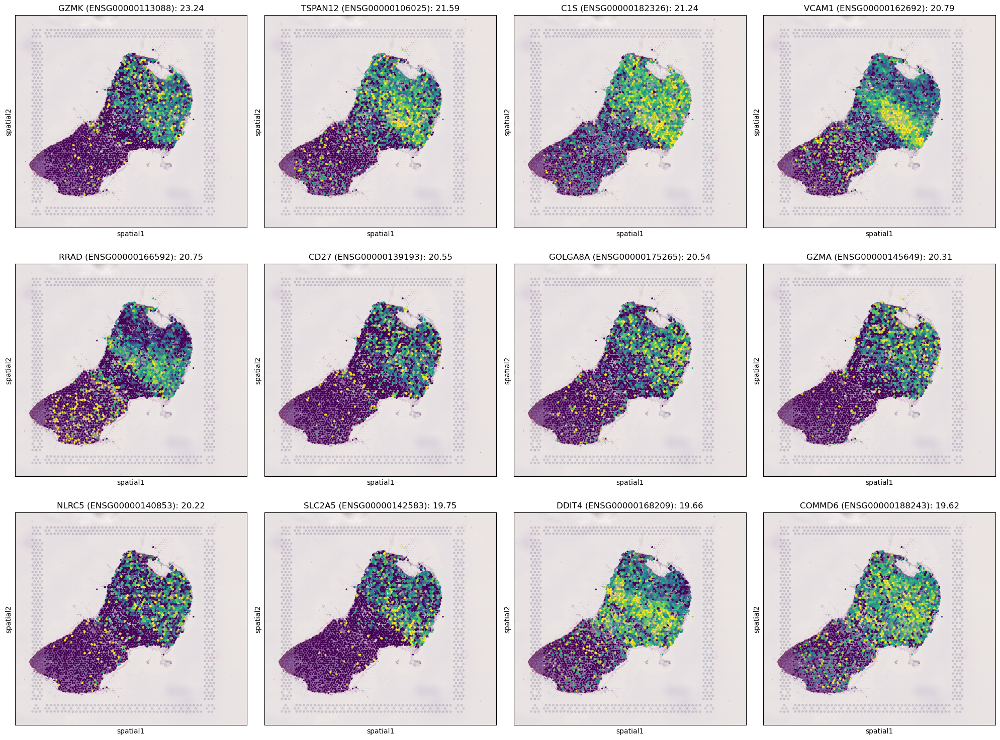

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]


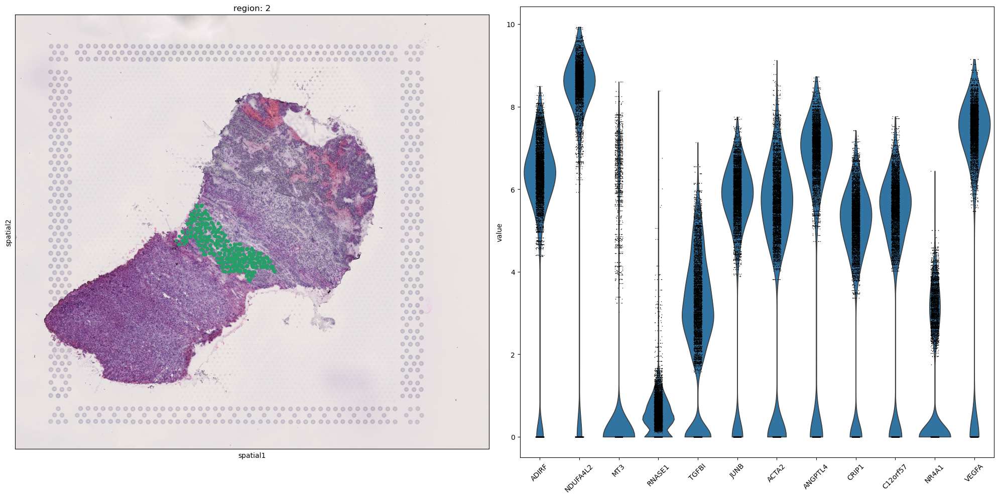

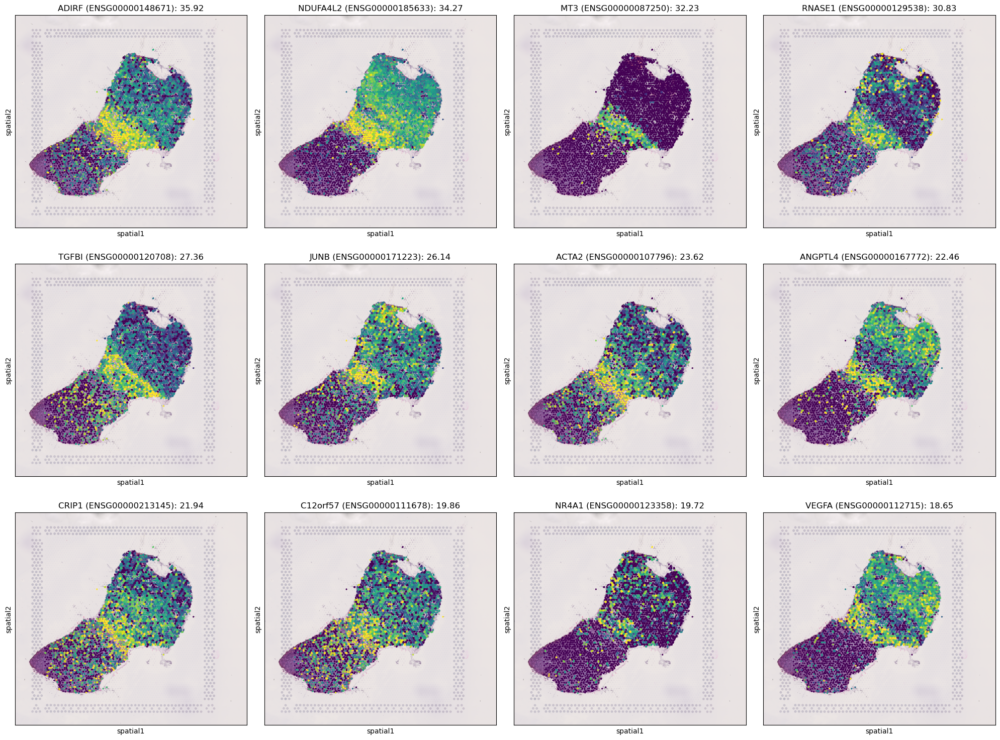

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]


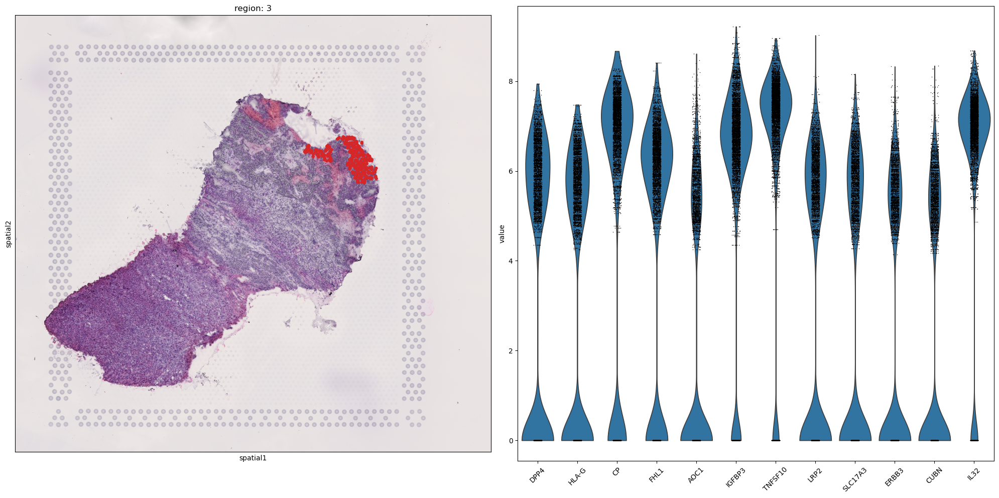

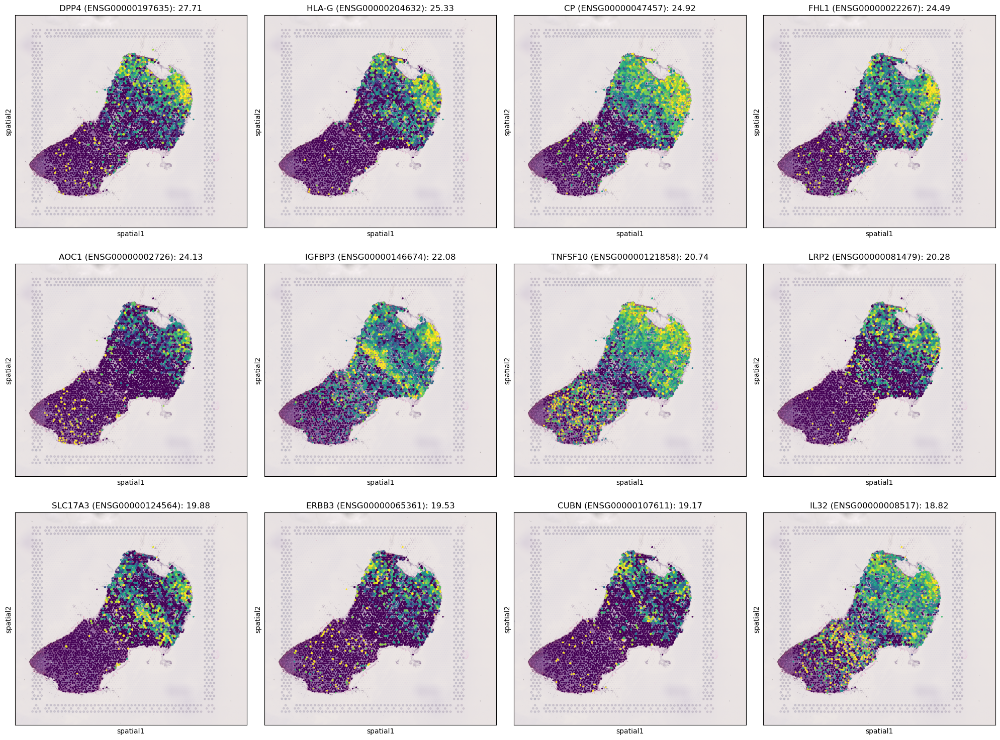

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]


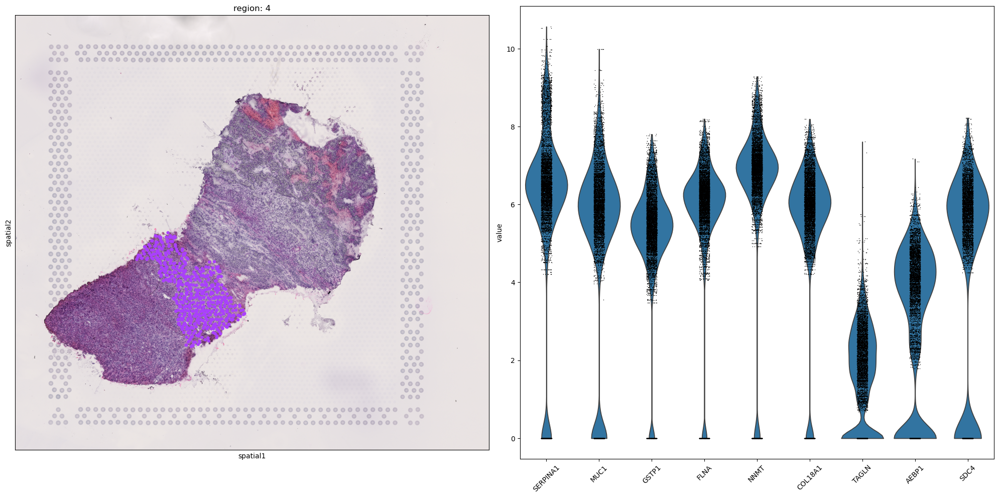

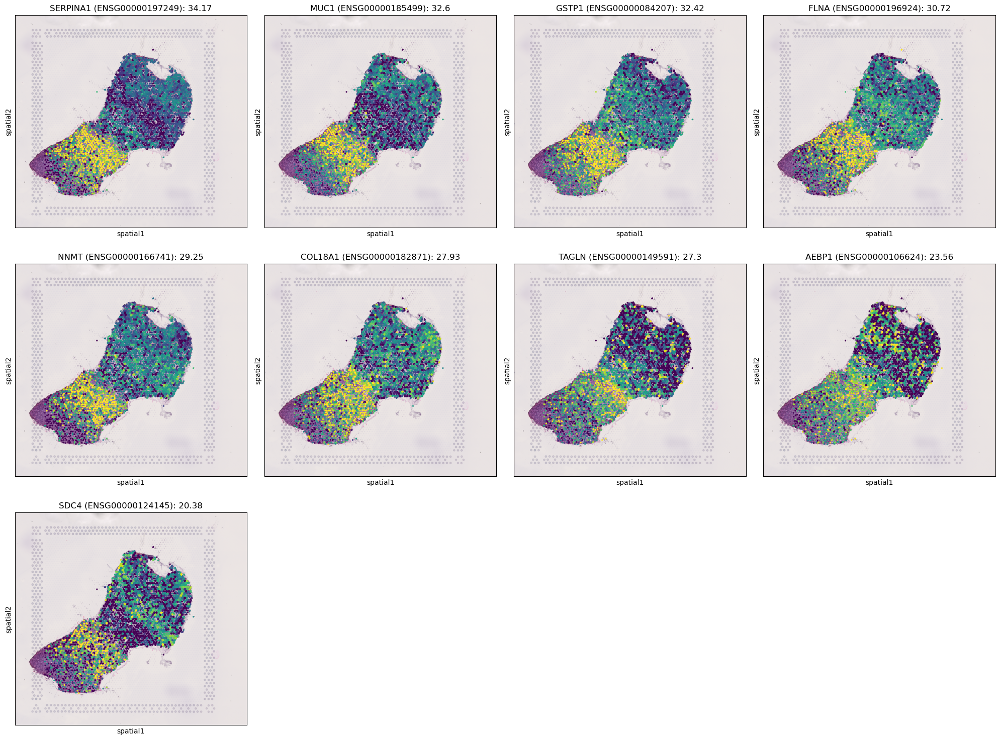

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]


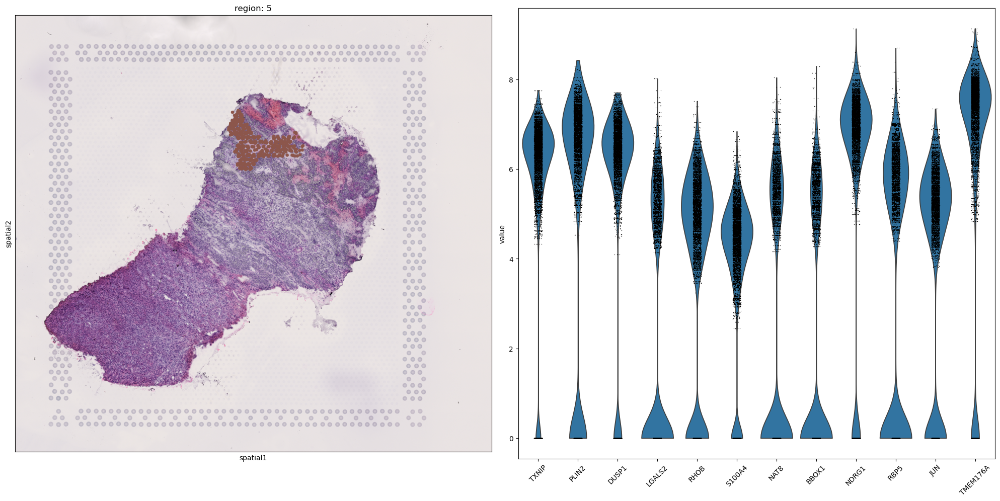

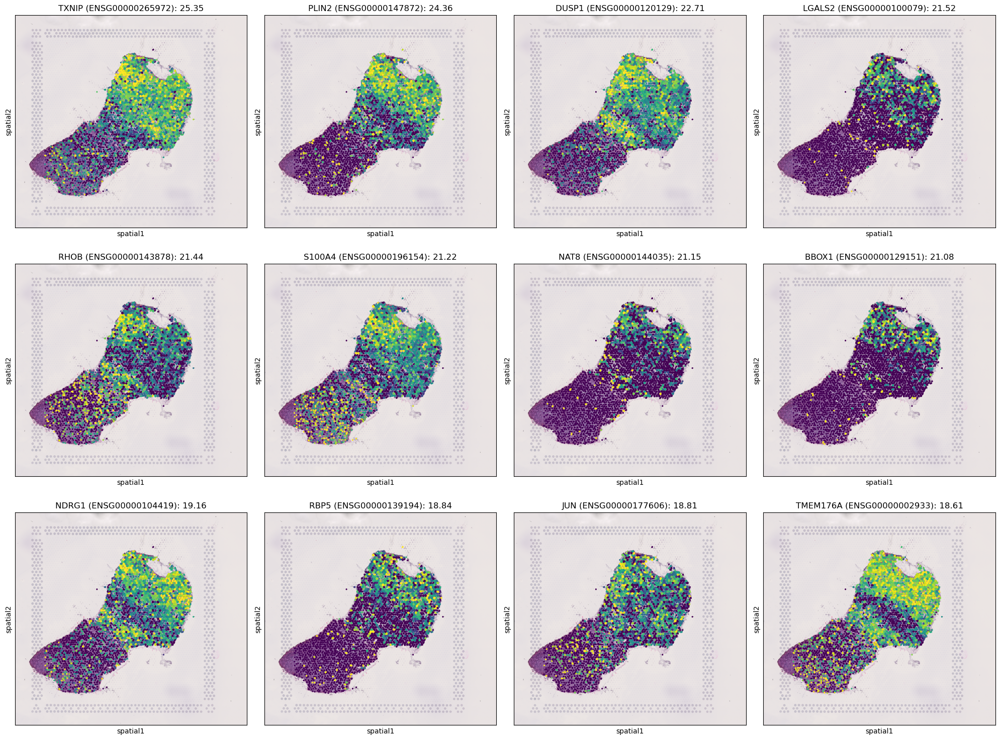

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]


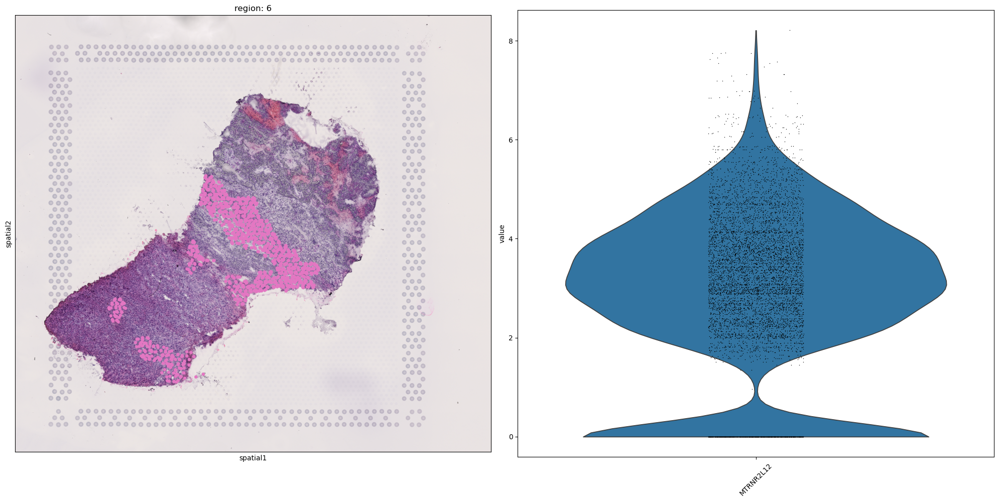

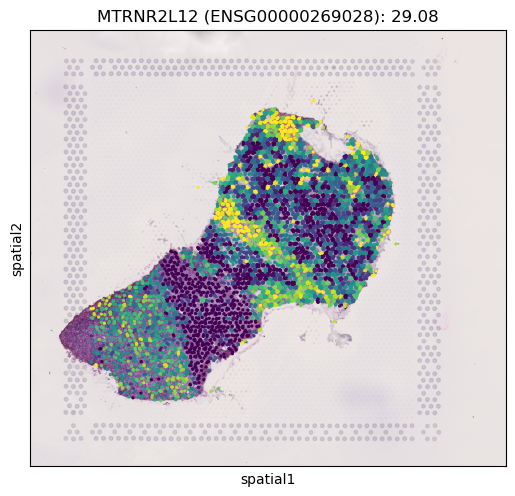

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]


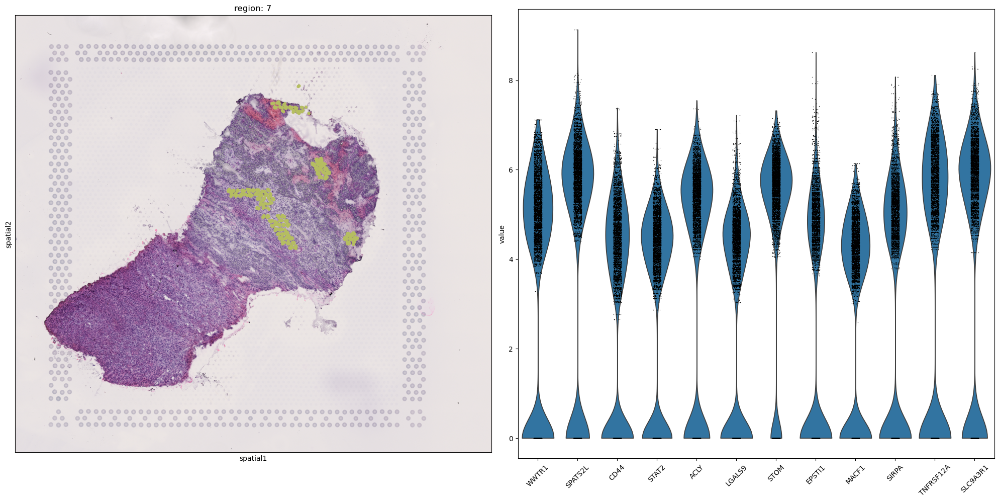

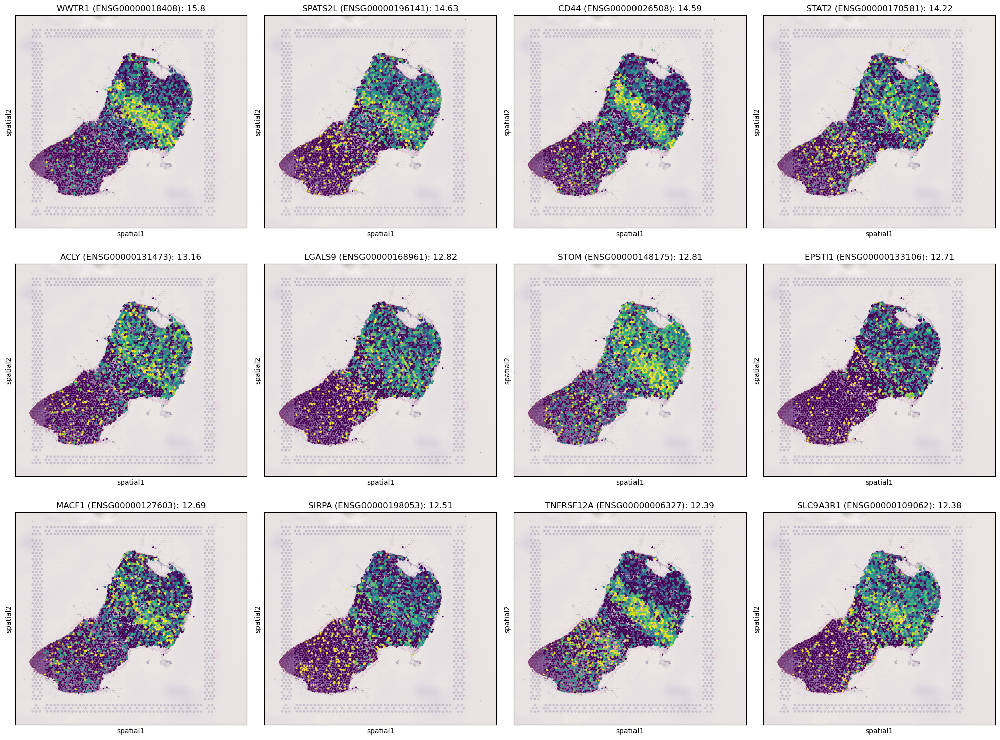

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]


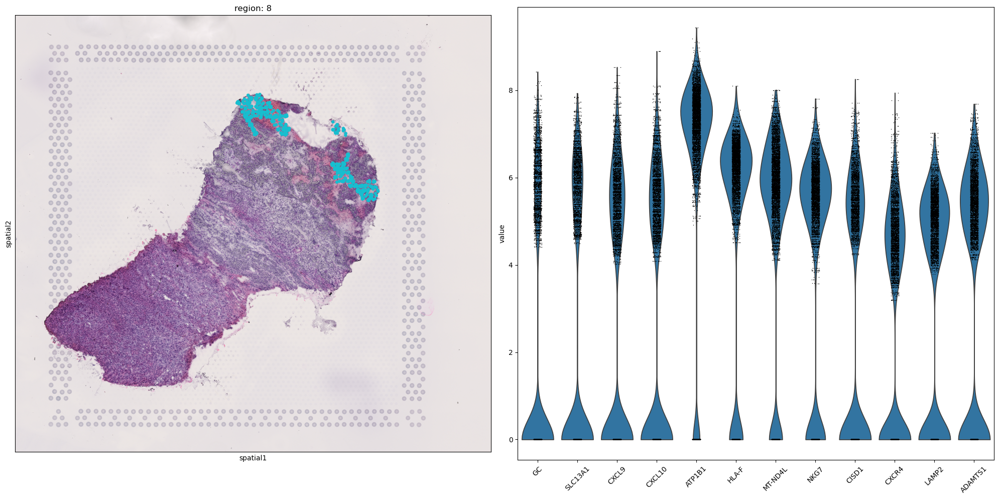

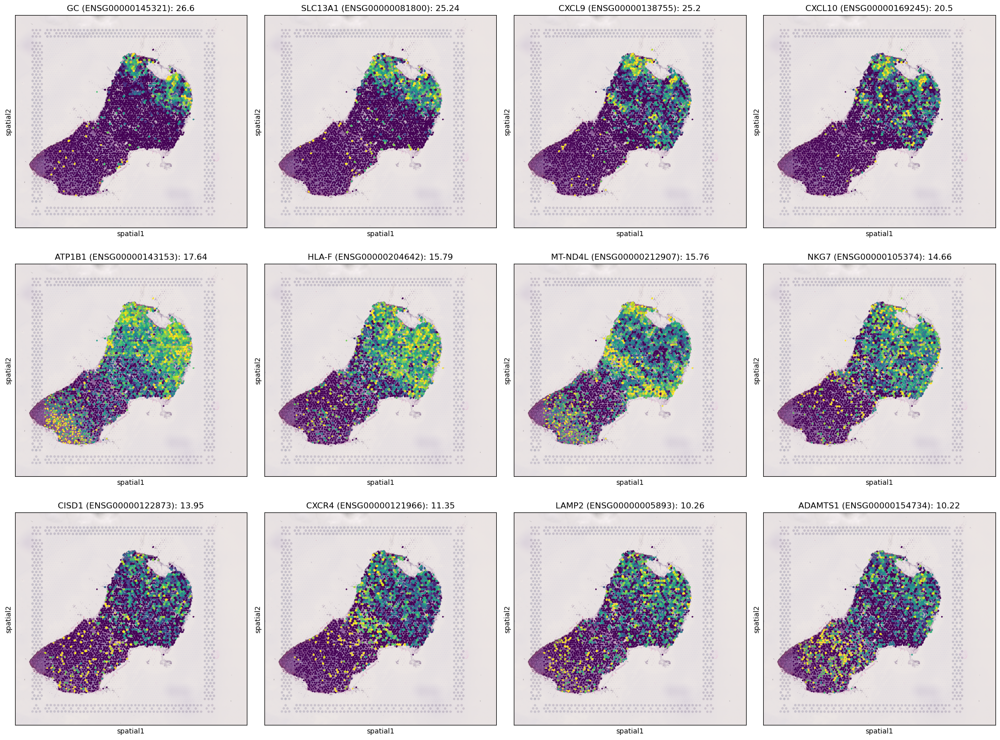

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]


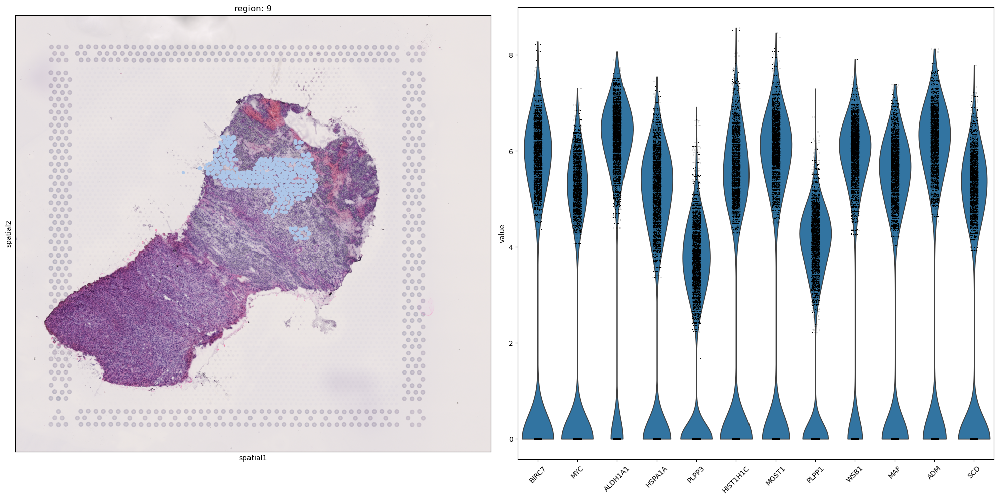

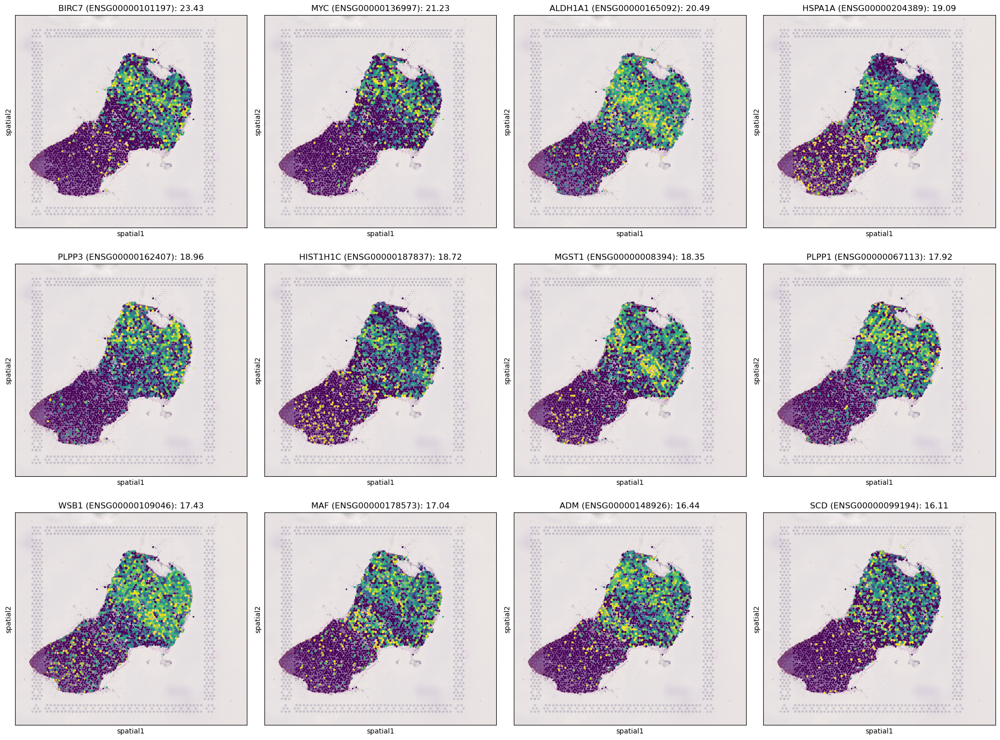

In [56]:
from hgctsvg.visualization import plot_domain_ct_svgs
groups = sorted(adata_RCC.obs['domain'].unique())
for g in groups:
    top_genes_RCC_group = top_genes_RCC_merged[top_genes_RCC_merged['region'] == g]
    top_genes_RCC_group = top_genes_RCC_group.sort_values('scores', ascending=False)
    scores = top_genes_RCC_group['scores'].tolist()
    indexes = top_genes_RCC_group.index.tolist()
    plot_domain_ct_svgs(adata_RCC, int(g), scores, indexes, use_raw=False)
    # plot_domain_de_genes(adata_RCC, int(g), top_genes[g]["scores"], top_genes[g]["indexes"], var_names_column='SYMBOL')
    # plot_domain_de_genes(adata_RCC, int(g), list(top_genes_RCC[g]["scores"]), list(top_genes_RCC[g]["names"]), var_names_column='SYMBOL')

In [57]:
1834 / 0.18601191, 2000 / 0.18601191

(9859.583722354122, 10751.999697223688)

In [58]:
library_id = list(adata_RCC.uns["spatial"].keys())[0]
adata_RCC.uns["spatial"][library_id]["scalefactors"]["tissue_segmentation_scalef"] = 1

vals = adata_RCC[:,'ENSG00000101443'].X
print(vals.shape)
nz = vals[vals > 0]
vmin = np.percentile(nz, 5)
vmax = np.percentile(nz, 95)
print(vmin, vmax)
sq.pl.spatial_segment(
    adata_RCC,
    seg_cell_id="segmentation",
    color='ENSG00000206503',
    library_key='library_id',
    # figsize=(32,32),
    vmin=vmin,seoul
    vmax=vmax,
    # crop_coord=[(1500,900,1800,1500)]
)

SyntaxError: invalid syntax. Perhaps you forgot a comma? (4179244957.py, line 16)

In [ ]:
gene_id = 'ENSG00000000971'
vals = adata_RCC[:,gene_id].X
# remove zeros
nz = vals[vals > 0]
vmin = np.percentile(nz, 5)
vmax = np.percentile(nz, 95)

sq.pl.spatial_scatter(
    adata_RCC,
    color=gene_id,
    use_raw=False,
)

In [ ]:
gene_id = 'ENSG00000000971'
vals = adata_aggr[:,gene_id].X
# remove zeros
nz = vals[vals > 0]
vmin = np.percentile(nz, 5)
vmax = np.percentile(nz, 95)

sq.pl.spatial_scatter(
    adata_aggr,
    color=gene_id,
    use_raw=False,
)

In [ ]:
adata_ENPT = load_ct_spatial_data("Epi_non-PT")
top_genes_ENPT = compute_domain_ct_svgs("Epi_non-PT", rank_by='scores')
plot_ct_marker_groups_heatmap(adata_ENPT, top_genes_ENPT)

In [ ]:
top_genes_ENPT_merged = create_svg_list(top_genes_ENPT)

# groups = adata_RCC.obs['leiden'].unique()
groups = sorted(top_genes_ENPT_merged['region'].unique(), key=lambda r: int(r))
print(len(top_genes_ENPT_merged), len(groups))
plot_domain_svgs(adata_ENPT, top_genes_ENPT_merged, groups, n_cols=len(groups), save=True)

In [ ]:
rcc_svgs = top_genes_RCC_merged.index
tissue_svgs = top_gene_list.index
union = rcc_svgs.union(tissue_svgs)
intersection = rcc_svgs.intersection(tissue_svgs)
len(rcc_svgs), len(tissue_svgs), len(union), len(intersection), len(intersection)/len(union)

In [ ]:
enpt_svgs = top_genes_ENPT_merged.index
union = enpt_svgs.union(tissue_svgs)
intersection = enpt_svgs.intersection(tissue_svgs)
union_ct = rcc_svgs.union(enpt_svgs)
intersection_ct = rcc_svgs.intersection(enpt_svgs)
len(enpt_svgs), len(tissue_svgs), len(union), len(intersection), len(intersection)/len(union), len(union_ct), len(intersection_ct), len(intersection_ct)/len(union_ct)

In [ ]:
groups = sorted(adata_ENPT.obs['domain'].unique())
for g in groups:
    top_genes_ENPT_group = top_genes_ENPT_merged[top_genes_ENPT_merged['region'] == g]
    top_genes_ENPT_group = top_genes_ENPT_group.sort_values('scores', ascending=False)
    scores = top_genes_ENPT_group['scores'].tolist()
    indexes = top_genes_ENPT_group.index.tolist()
    if len(scores) > 0:
        plot_domain_ct_svgs(adata_ENPT, int(g), scores, indexes, use_raw=False)